<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/SPEA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.7/72.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 3.9 MB/s eta 0:00:00

             SPEA2 OPTIMISED PORTFOLIO

RELIANCE.NS    : 12.62%
HDFCBANK.NS    : 9.16%
ICICIBANK.NS   : 6.32%
INFY.NS        : 9.64%
TCS.NS         : 8.77%
ITC.NS         : 9.25%
LT.NS          : 10.70%
SBIN.NS        : 10.43%
BHARTIARTL.NS  : 12.84%
HINDUNILVR.NS  : 10.24%

================ METRICS =================

Return             0.1907
Volatility         0.1403
CVaR               0.3033
Turnover           0.1369
Diversification    9.6888
Sharpe             1.3593
Score              3.0407
Name: 24, dtype: float64


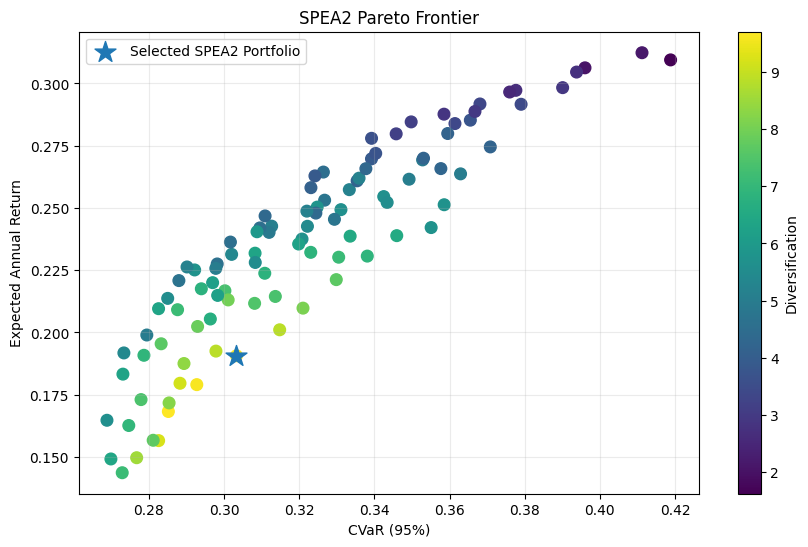

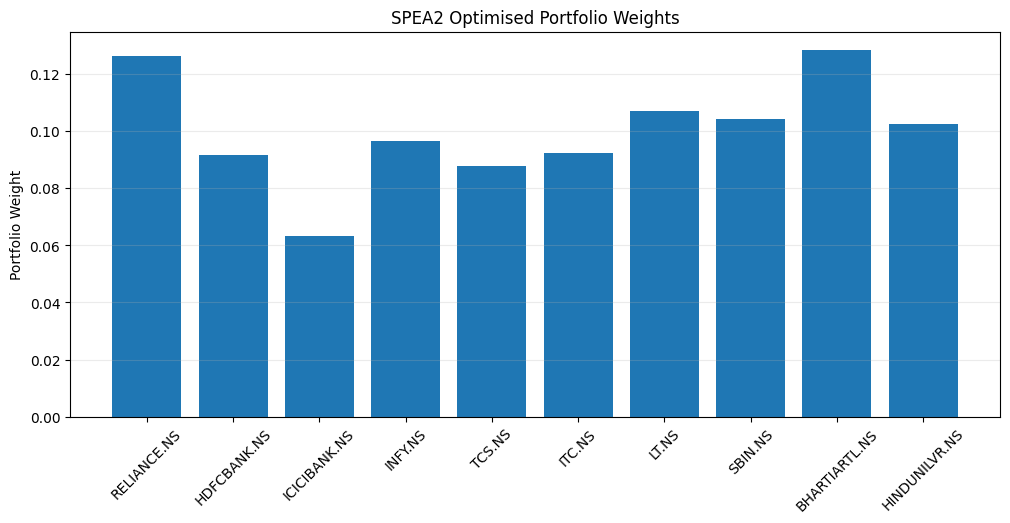


================ TOP PARETO SOLUTIONS ================

    Return  Volatility    CVaR  Turnover  Diversification  Sharpe   Score
24  0.1907      0.1403  0.3033    0.1369           9.6888  1.3593  3.0407
5   0.1683      0.1331  0.2852    0.1293           9.7094  1.2641  3.0369
59  0.1791      0.1363  0.2928    0.1594           9.6454  1.3141  3.0210
47  0.1796      0.1348  0.2883    0.2368           9.1448  1.3328  2.9370
29  0.1925      0.1399  0.2979    0.2318           8.8648  1.3765  2.9188
31  0.2011      0.1453  0.3148    0.2165           8.8863  1.3839  2.8701
3   0.1566      0.1317  0.2826    0.2414           9.2129  1.1890  2.8436
62  0.1875      0.1360  0.2894    0.3593           8.3712  1.3794  2.7942
46  0.2131      0.1424  0.3011    0.4004           7.9783  1.4964  2.7894
91  0.2024      0.1391  0.2930    0.4509           7.8469  1.4556  2.7282


In [ ]:
# ================================================================
# SPEA2 MULTI-OBJECTIVE QUANT PORTFOLIO OPTIMISATION
# Return ↑ | CVaR ↓ | Turnover ↓ | Diversification ↑
# ================================================================

!pip -q install yfinance pymoo

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.spea2 import SPEA2
from pymoo.optimize import minimize

np.random.seed(42)

# ================================================================
# 1. DATA
# ================================================================

tickers = [
    "RELIANCE.NS",
    "HDFCBANK.NS",
    "ICICIBANK.NS",
    "INFY.NS",
    "TCS.NS",
    "ITC.NS",
    "LT.NS",
    "SBIN.NS",
    "BHARTIARTL.NS",
    "HINDUNILVR.NS"
]

prices = yf.download(
    tickers,
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)["Close"].dropna()

returns = prices.pct_change().dropna()

n_assets = len(tickers)

# Annualised expected return
mu = returns.mean().values * 252

# Annualised covariance
cov = returns.cov().values * 252

# Equal-weight reference portfolio
reference = np.ones(n_assets) / n_assets


# ================================================================
# 2. PORTFOLIO METRICS
# ================================================================

def metrics(w):

    daily = returns.values @ w

    # Annual return
    annual_return = np.dot(
        w,
        mu
    )

    # Annual volatility
    volatility = np.sqrt(
        w @ cov @ w
    )

    # ------------------------------------------------------------
    # 95% CVaR
    # ------------------------------------------------------------

    var95 = np.percentile(
        daily,
        5
    )

    tail = daily[
        daily <= var95
    ]

    cvar = (
        -tail.mean() * np.sqrt(252)
        if len(tail) > 0
        else 0
    )

    # ------------------------------------------------------------
    # Turnover
    # ------------------------------------------------------------

    turnover = np.sum(
        np.abs(
            w - reference
        )
    )

    # ------------------------------------------------------------
    # Diversification
    # ------------------------------------------------------------

    hhi = np.sum(
        w ** 2
    )

    diversification = (
        1 / hhi
    )

    # ------------------------------------------------------------
    # Sharpe
    # ------------------------------------------------------------

    sharpe = (
        annual_return / volatility
        if volatility > 0
        else 0
    )

    return (
        annual_return,
        volatility,
        cvar,
        turnover,
        diversification,
        sharpe
    )


# ================================================================
# 3. SPEA2 PORTFOLIO PROBLEM
# ================================================================

class PortfolioProblem(
    ElementwiseProblem
):

    def __init__(self):

        super().__init__(
            n_var=n_assets,
            n_obj=4,
            xl=np.zeros(
                n_assets
            ),
            xu=np.ones(
                n_assets
            )
        )

    def _evaluate(
        self,
        w,
        out,
        *args,
        **kwargs
    ):

        # Long-only
        w = np.maximum(
            w,
            0
        )

        # Fully invested
        if w.sum() == 0:

            w = (
                np.ones(n_assets)
                / n_assets
            )

        else:

            w = (
                w / w.sum()
            )

        (
            ret,
            vol,
            cvar,
            turnover,
            diversification,
            sharpe
        ) = metrics(w)

        # Pymoo minimises all objectives
        out["F"] = np.array([

            -ret,                # Return ↑

            cvar,                # CVaR ↓

            turnover,            # Turnover ↓

            -diversification     # Diversification ↑
        ])


# ================================================================
# 4. SPEA2
# ================================================================

problem = PortfolioProblem()

algorithm = SPEA2(
    pop_size=100,
    n_offsprings=100
)

result = minimize(
    problem,
    algorithm,
    ("n_gen", 150),
    seed=42,
    verbose=False
)


# ================================================================
# 5. PARETO SOLUTIONS
# ================================================================

pareto_weights = result.X

valid_weights = []
rows = []

for w in pareto_weights:

    # Long-only
    w = np.maximum(
        w,
        0
    )

    if w.sum() == 0:
        continue

    # Fully invested
    w = (
        w / w.sum()
    )

    (
        ret,
        vol,
        cvar,
        turnover,
        diversification,
        sharpe
    ) = metrics(w)

    valid_weights.append(
        w
    )

    rows.append([
        ret,
        vol,
        cvar,
        turnover,
        diversification,
        sharpe
    ])


pareto_weights = np.array(
    valid_weights
)

results = pd.DataFrame(
    rows,
    columns=[
        "Return",
        "Volatility",
        "CVaR",
        "Turnover",
        "Diversification",
        "Sharpe"
    ]
)


# ================================================================
# 6. REMOVE DUPLICATES
# ================================================================

results = results.drop_duplicates(
    subset=[
        "Return",
        "CVaR",
        "Turnover",
        "Diversification"
    ]
).reset_index(
    drop=True
)

pareto_weights = pareto_weights[
    results.index
]


# ================================================================
# 7. BALANCED PARETO SCORE
# ================================================================

def normalize(x):

    return (
        (x - x.min())
        /
        (
            x.max()
            - x.min()
            + 1e-12
        )
    )


return_score = normalize(
    results["Return"]
)

cvar_score = (
    1 -
    normalize(
        results["CVaR"]
    )
)

turnover_score = (
    1 -
    normalize(
        results["Turnover"]
    )
)

diversification_score = normalize(
    results["Diversification"]
)

results["Score"] = (
    return_score
    +
    cvar_score
    +
    turnover_score
    +
    diversification_score
)


# ================================================================
# 8. SELECT BALANCED PORTFOLIO
# ================================================================

best_idx = results[
    "Score"
].idxmax()

best_weights = pareto_weights[
    best_idx
]

best_weights = np.maximum(
    best_weights,
    0
)

best_weights /= (
    best_weights.sum()
)


# ================================================================
# 9. FINAL PORTFOLIO
# ================================================================

print(
    "\n================================================"
)

print(
    "             SPEA2 OPTIMISED PORTFOLIO"
)

print(
    "================================================\n"
)

for ticker, weight in zip(
    tickers,
    best_weights
):

    print(
        f"{ticker:15s}: {weight:.2%}"
    )


# ================================================================
# 10. METRICS
# ================================================================

print(
    "\n================ METRICS =================\n"
)

print(
    results.iloc[
        best_idx
    ].round(4)
)


# ================================================================
# 11. PARETO FRONTIER
# ================================================================

plt.figure(
    figsize=(10, 6)
)

scatter = plt.scatter(
    results["CVaR"],
    results["Return"],
    c=results[
        "Diversification"
    ],
    s=70
)

plt.scatter(
    results.iloc[
        best_idx
    ]["CVaR"],
    results.iloc[
        best_idx
    ]["Return"],
    marker="*",
    s=250,
    label="Selected SPEA2 Portfolio"
)

plt.xlabel(
    "CVaR (95%)"
)

plt.ylabel(
    "Expected Annual Return"
)

plt.title(
    "SPEA2 Pareto Frontier"
)

plt.colorbar(
    scatter,
    label="Diversification"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.show()


# ================================================================
# 12. PORTFOLIO WEIGHTS
# ================================================================

plt.figure(
    figsize=(12, 5)
)

plt.bar(
    tickers,
    best_weights
)

plt.xticks(
    rotation=45
)

plt.ylabel(
    "Portfolio Weight"
)

plt.title(
    "SPEA2 Optimised Portfolio Weights"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.show()


# ================================================================
# 13. TOP PARETO SOLUTIONS
# ================================================================

print(
    "\n================ TOP PARETO SOLUTIONS ================\n"
)

print(
    results
    .sort_values(
        "Score",
        ascending=False
    )
    .head(10)
    .round(4)
)